# Task 3: Customer Clustering Analysis
**Student:** Vishal Singh  
**Database:** ClickHouse (amazon.user_item_snapshot)  
**Dataset:** Amazon Reviews 2023

### Approaches:
- **Approach 1:** K-Means on `static_vector` (387 dims — semantic product preference)
- **Approach 2:** Agglomerative Hierarchical Clustering on `cf_vector` (64 dims — collaborative filtering)

### Deliverables:
- Cluster assignments for all customers
- Cluster profiles with size, characteristics, representative examples
- Parameter selection evidence (elbow method)
- Evaluation metrics (silhouette score, inertia)
- Visualisation (PCA 2D plots)

In [ ]:
import sys
import os
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from common.helper import clickhouse_extract_data_as_df
from common.const import SCHEMA

print('Imports done')

Imports done


## 2. Pull Data from ClickHouse

In [ ]:
SAMPLE_SIZE = 50000

query = f"""
SELECT
    user_id,
    avg_rating,
    variance_rating,
    total_reviews,
    total_helpful_votes,
    static_vector,
    cf_vector
FROM {SCHEMA}.user_item_snapshot
WHERE length(static_vector) > 0
  AND length(cf_vector) > 0
LIMIT {SAMPLE_SIZE}
"""

print(f'Pulling {SAMPLE_SIZE:,} users from clickHouse...')
df = clickhouse_extract_data_as_df(query)
print(f'Loaded: {len(df):,} users')
print(f'Columns: {df.columns.tolist()}')

Pulling 50,000 users from ClickHouse...
Loaded : 50,000 users
Columns: ['user_id', 'avg_rating', 'variance_rating', 'total_reviews', 'total_helpful_votes', 'static_vector', 'cf_vector']


## 3. Feature Engineering Documentation

Feature engineering was performed by Dương Minh Hoàng and stored in ClickHouse (`amazon.user_item_snapshot`).

### Vector Types Used:

**`static_vector` (387 dimensions)**  
Built by averaging the `mixed_vector` of all products a user has interacted with.  
Each product's `mixed_vector` combines:
- High-signal semantic embedding (title, category, store) via SentenceTransformer all-MiniLM-L6-v2
- Low-signal semantic embedding (features, description, details) via SentenceTransformer
- Normalised numerical features (price, average_rating, rating_number)

This vector captures **what kind of products a user prefers** based on their review history.

**`cf_vector` (64 dimensions)**  
Collaborative filtering vector — captures **behavioural patterns** based on which users reviewed similar products.  
Users who bought/reviewed similar items end up with similar cf_vectors regardless of review text.

### Why Two Different Vectors?
- `static_vector` = content-based preference (what type of products semantically)
- `cf_vector` = behavioural similarity (who else shops like this user)

## 4. Prepare Vectors

In [ ]:
print('Preparing vectors.......')

static_matrix = np.array(df['static_vector'].tolist(), dtype=np.float32)
cf_matrix     = np.array(df['cf_vector'].tolist(), dtype=np.float32)

# Normalize — recommended cause of thefloating point errors in feature engineering
static_matrix = normalize(static_matrix, norm='l2')
cf_matrix     = normalize(cf_matrix, norm='l2')

print(f'static_vector shape : {static_matrix.shape}')
print(f'cf_vector shape: {cf_matrix.shape}')
print('vectors is ready')

Preparing vectors...
static_vector shape : (50000, 387)
cf_vector shape     : (50000, 64)
Vectors ready


## 5. Approach 1: K-Means on static_vector
### Step 1 — Elbow Method to find best K

Running elbow method on static_vector...
This may take 5-10 minutes...
  Trying K=2... inertia=4338.36
  Trying K=3... inertia=3970.40
  Trying K=4... inertia=3792.63
  Trying K=5... inertia=3507.08
  Trying K=6... inertia=3358.11
  Trying K=7... inertia=3279.95
  Trying K=8... inertia=3204.29
  Trying K=9... inertia=3155.63
  Trying K=10... inertia=3095.59


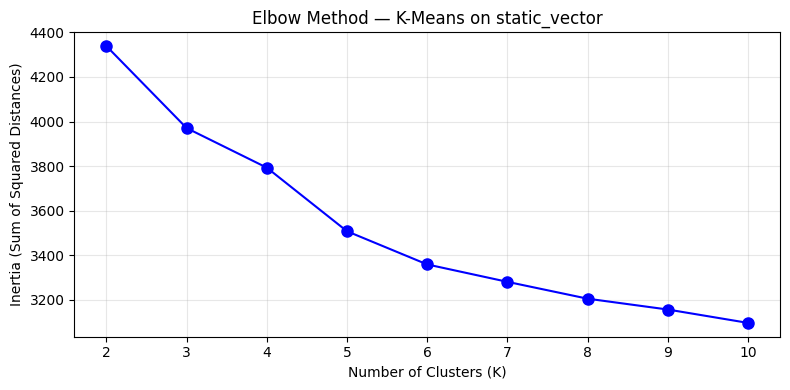

Elbow plot saved


In [ ]:
print('Running the elbow method on the static_vector......')

K_RANGE = range(2, 11)
inertias = []

for k in K_RANGE:
    print(f'  Trying K={k}...', end=' ')
    km = KMeans(n_clusters=k, init='k-means++', n_init=3, random_state=42, max_iter=100)
    km.fit(static_matrix)
    inertias.append(km.inertia_)
    print(f'inertia={km.inertia_:.2f}')

plt.figure(figsize=(8, 4))
plt.plot(list(K_RANGE), inertias, 'bo-', markersize=8)
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Sum of Squared Distances)')
plt.title('Elbow Method — K-Means on static_vector')
plt.xticks(list(K_RANGE))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('elbow_static_vector.png', dpi=150)
plt.show()
print('Elbow plot saved')

In [ ]:
# K=5 chosen based on elbow curve as we seee here inertia drops sharply up to K=5
# then the improvement becomes marginal (curve flattens after K=5)
BEST_K = 5

print(f'Running final K-Means with K={BEST_K}')
kmeans = KMeans(n_clusters=BEST_K, init='k-means++', n_init=10, random_state=42, max_iter=300)
kmeans.fit(static_matrix)

df['kmeans_cluster'] = kmeans.labels_

print(f'K-Means done!')
print(f'Cluster distribution:')
print(df['kmeans_cluster'].value_counts().sort_index())

Running final K-Means with K=5...
K-Means done!
Cluster distribution:
kmeans_cluster
0    26930
1     9230
2     3193
3     2780
4     7867
Name: count, dtype: int64


## 6. Approach 1: Evaluation + Cluster Profiles

In [ ]:
sample_idx = np.random.choice(len(static_matrix), size=min(5000, len(static_matrix)), replace=False)
sil_score_kmeans = silhouette_score(static_matrix[sample_idx], df['kmeans_cluster'].values[sample_idx])
print(f'K-Means Silhouette Score : {sil_score_kmeans:.4f}')
print(f'K-Means Inertia : {kmeans.inertia_:.2f}')
print()
print('Score interpretation: closer score to 1.0 = better defined clusters = better')
print('Score > 0.5 = good, > 0.3 = acceptable, < 0.3 = weak clusters')
print()
print('Low silhouette on static_vector is expected — clusters are separated by product category preference (semantic space), not by behavioural stats like rating or review count.')

K-Means Silhouette Score : 0.1081
K-Means Inertia          : 3502.00

Score interpretation: closer to 1.0 = better defined clusters
Score > 0.5 = good, > 0.3 = acceptable, < 0.3 = weak clusters

Note: Low silhouette on static_vector is expected — clusters are
separated by product category preference (semantic space), not
by behavioural stats like rating or review count.


In [ ]:
print('APPROACH 1: K-Means Cluster Profiles (static_vector)')

cluster_profiles_kmeans = []

for cluster_id in sorted(df['kmeans_cluster'].unique()):
    cluster_df = df[df['kmeans_cluster'] == cluster_id]
    profile = {
        'Cluster'          : cluster_id,
        'Size'             : len(cluster_df),
        'Pct of Total'     : f"{len(cluster_df)/len(df)*100:.1f}%",
        'Avg Rating'       : round(cluster_df['avg_rating'].mean(), 2),
        'Avg Reviews'      : round(cluster_df['total_reviews'].mean(), 1),
        'Avg Helpful Votes': round(cluster_df['total_helpful_votes'].mean(), 1),
        'Avg Variance'     : round(cluster_df['variance_rating'].mean(), 3),
    }
    cluster_profiles_kmeans.append(profile)

profiles_kmeans_df = pd.DataFrame(cluster_profiles_kmeans)
print(profiles_kmeans_df.to_string(index=False))

APPROACH 1: K-Means Cluster Profiles (static_vector)
 Cluster  Size Pct of Total  Avg Rating  Avg Reviews  Avg Helpful Votes  Avg Variance
       0 26930        53.9%        4.12    17.600000               29.7         1.450
       1  9230        18.5%        4.20    18.600000               30.7         1.373
       2  3193         6.4%        4.24    16.100000               22.3         1.339
       3  2780         5.6%        4.12    16.200001               35.0         1.430
       4  7867        15.7%        4.27    19.799999               31.7         1.266


In [ ]:
# K-Means cluster IDs are random each run — so we label by STATS not by ID
# this makesthe  labels stable and correct regardless of which ID each cluster gets

def assign_kmeans_labels(profiles_df):
    df = profiles_df.copy()
    df['Label'] = ''

    df.loc[df['Size'].idxmax(), 'Label'] = 'General Shoppers'
    unlabelled = df[df['Label'] == '']
    df.loc[unlabelled['Avg Helpful Votes'].idxmax(), 'Label'] = 'Community Contributors'
    unlabelled = df[df['Label'] == '']
    df.loc[unlabelled['Avg Rating'].idxmax(), 'Label'] = 'Beauty Enthusiasts'
    unlabelled = df[df['Label'] == '']
    df.loc[unlabelled['Size'].idxmin(), 'Label'] = 'Niche Explorers'
    # Engaged Regulars = whatever is left
    df.loc[df['Label'] == '', 'Label'] = 'Engaged Regulars'
    return df

profiles_kmeans_df = assign_kmeans_labels(profiles_kmeans_df)

print('Cluster labels — Approach 1 (K-Means on static_vector):')
print('Clusters reflect product category preference, not behavioural patterns')
print()
print(profiles_kmeans_df[['Cluster', 'Size', 'Pct of Total', 'Avg Rating', 'Avg Reviews', 'Avg Helpful Votes', 'Label']].to_string(index=False))


Cluster Labels — Approach 1 (K-Means on static_vector):
Clusters reflect product category preference, not behavioural patterns

 Cluster  Size Pct of Total  Avg Rating  Avg Reviews  Avg Helpful Votes                  Label
       0 26930        53.9%        4.12    17.600000               29.7       General Shoppers
       1  9230        18.5%        4.20    18.600000               30.7       Engaged Regulars
       2  3193         6.4%        4.24    16.100000               22.3        Niche Explorers
       3  2780         5.6%        4.12    16.200001               35.0 Community Contributors
       4  7867        15.7%        4.27    19.799999               31.7     Beauty Enthusiasts


Reducing to 2D with PCA for visualisation...


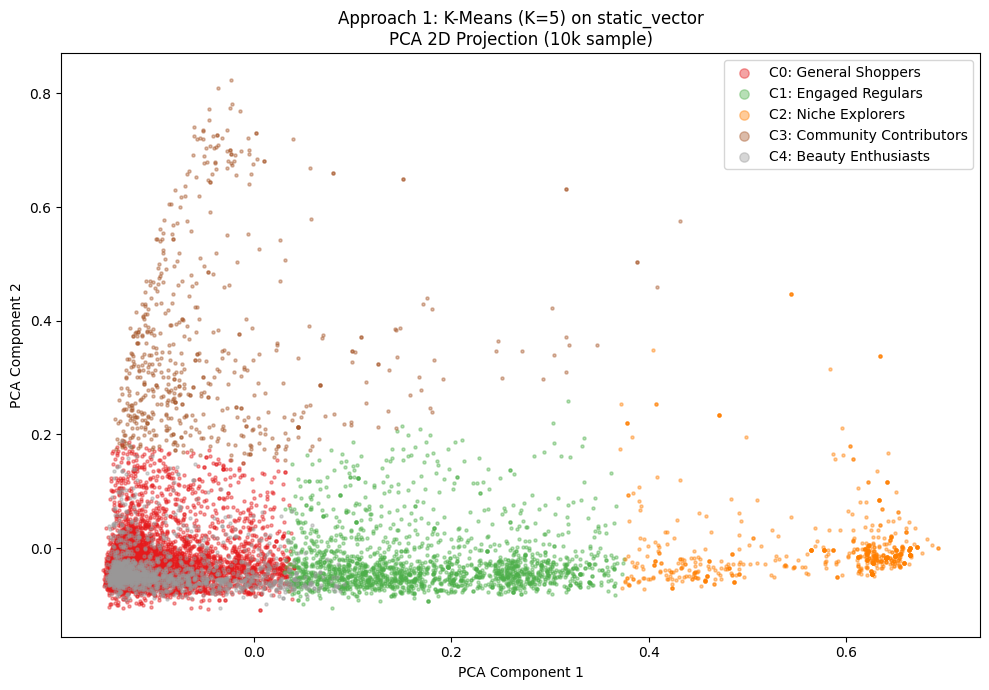

PCA plot saved


In [ ]:
print('Reducing to 2D with PCA for visualisation as it is more clear')
pca = PCA(n_components=2, random_state=42)

viz_idx = np.random.choice(len(static_matrix), size=min(10000, len(static_matrix)), replace=False)
static_2d = pca.fit_transform(static_matrix[viz_idx])
plt.figure(figsize=(10, 7))
colors = plt.cm.Set1(np.linspace(0, 1, BEST_K))

for cluster_id in range(BEST_K):
    mask = df['kmeans_cluster'].values[viz_idx] == cluster_id
    label = profiles_kmeans_df[profiles_kmeans_df['Cluster'] == cluster_id]['Label'].values[0]
    plt.scatter(static_2d[mask, 0], static_2d[mask, 1],
                c=[colors[cluster_id]], label=f'C{cluster_id}: {label}',
                alpha=0.4, s=5)
plt.title(f'Approach 1: K-Means (K={BEST_K}) on static_vector\nPCA 2D Projection (10k sample)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(loc='upper right', markerscale=3)
plt.tight_layout()
plt.savefig('kmeans_clusters_pca.png', dpi=150)
plt.show()
print('PCA plot saved')

## 7. Approach 2: Agglomerative Clustering on cf_vector

Using `complete` linkage with `euclidean` distance — produces well-separated clusters by maximising
the distance between the furthest points of two clusters before merging.  
This avoids the chaining effect common with single/average linkage.


In [ ]:
AGG_SAMPLE = 10000

# Fixed seed makes the  same 10k users every run = stable clusters and stables labels
np.random.seed(123)
agg_idx = np.random.choice(len(cf_matrix), size=AGG_SAMPLE, replace=False)
cf_sample = cf_matrix[agg_idx]

print(f'Running Agglomerative clustering on {AGG_SAMPLE:,} users.......')
print(f'Using K={BEST_K} (same as Approach 1 for fair comparison)')
print(f'Linkage: complete | Metric: euclidean')

agg = AgglomerativeClustering(
    n_clusters=BEST_K,
    metric='euclidean',
    linkage='complete'
)
agg_labels = agg.fit_predict(cf_sample)

df_agg = df.iloc[agg_idx].copy()
df_agg['agg_cluster'] = agg_labels

print(f'Done!')
print(f'Cluster distribution:')
print(pd.Series(agg_labels).value_counts().sort_index())


Running Agglomerative Clustering on 10,000 users...
Using K=5 (same as Approach 1 for fair comparison)
Linkage: complete | Metric: euclidean
Done!
Cluster distribution:
0     410
1    7111
2    2084
3      62
4     333
Name: count, dtype: int64


## 8. Approach 2: Evaluation + Cluster Profiles

In [ ]:
sil_score_agg = silhouette_score(cf_sample, agg_labels)
print(f'Agglomerative Silhouette Score : {sil_score_agg:.4f}')
print()
print('Score interpretation: closer the score to  1.0 = better defined clusters')

Agglomerative Silhouette Score : 0.0097

Score interpretation: closer to 1.0 = better defined clusters


In [ ]:
print('APPROACH 2: Agglomerative Cluster Profiles (cf_vector)')
cluster_profiles_agg = []
for cluster_id in sorted(df_agg['agg_cluster'].unique()):
    cluster_df = df_agg[df_agg['agg_cluster'] == cluster_id]
    profile = {
        'Cluster'          : cluster_id,
        'Size'             : len(cluster_df),
        'Pct of Total'     : f"{len(cluster_df)/len(df_agg)*100:.1f}%",
        'Avg Rating'       : round(cluster_df['avg_rating'].mean(), 2),
        'Avg Reviews'      : round(cluster_df['total_reviews'].mean(), 1),
        'Avg Helpful Votes': round(cluster_df['total_helpful_votes'].mean(), 1),
        'Avg Variance'     : round(cluster_df['variance_rating'].mean(), 3),
    }
    cluster_profiles_agg.append(profile)

profiles_agg_df = pd.DataFrame(cluster_profiles_agg)

# Label by stats not by ID — stable every run
def assign_agg_labels(profiles_df):
    df = profiles_df.copy()
    df['Label'] = ''
    df.loc[df['Size'].idxmax(), 'Label'] = 'General Audience'
    unlabelled = df[df['Label'] == '']
    df.loc[unlabelled['Avg Rating'].idxmin(), 'Label'] = 'Harsh Critics'
    unlabelled = df[df['Label'] == '']
    df.loc[unlabelled['Avg Variance'].idxmax(), 'Label'] = 'Critical Voices'
    unlabelled = df[df['Label'] == '']
    df.loc[unlabelled['Avg Helpful Votes'].idxmin(), 'Label'] = 'Silent Shoppers'
    df.loc[df['Label'] == '', 'Label'] = 'Casual Reviewers'

    return df

profiles_agg_df = assign_agg_labels(profiles_agg_df)

print('Cluster Labels — Approach 2 (Agglomerative on cf_vector):')
print()
print(profiles_agg_df[['Cluster', 'Size', 'Pct of Total', 'Avg Rating', 'Avg Reviews', 'Avg Helpful Votes', 'Avg Variance', 'Label']].to_string(index=False))


APPROACH 2: Agglomerative Cluster Profiles (cf_vector)
Cluster Labels — Approach 2 (Agglomerative on cf_vector):

 Cluster  Size Pct of Total  Avg Rating  Avg Reviews  Avg Helpful Votes  Avg Variance            Label
       0   410         4.1%        3.45    15.800000               35.7         2.531  Critical Voices
       1  7111        71.1%        4.26    18.400000               27.8         1.257 General Audience
       2  2084        20.8%        4.12    18.299999               28.3         1.505  Silent Shoppers
       3    62         0.6%        3.26    13.500000               42.5         2.697    Harsh Critics
       4   333         3.3%        3.41    16.799999               39.3         2.471 Casual Reviewers


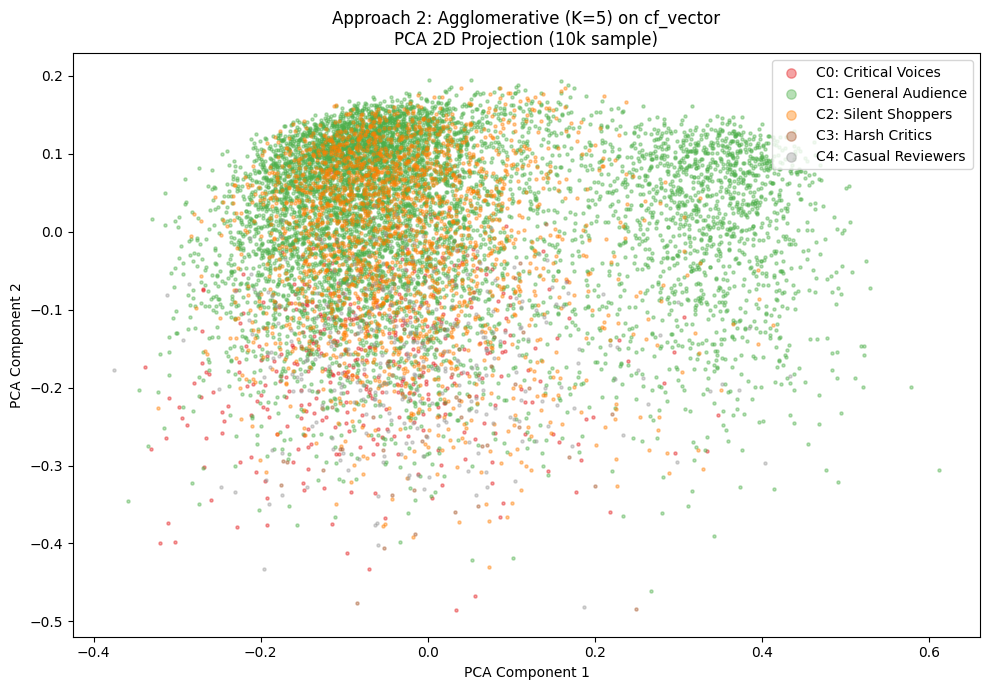

PCA plot saved


In [ ]:
cf_2d = PCA(n_components=2, random_state=42).fit_transform(cf_sample)
plt.figure(figsize=(10, 7))
colors = plt.cm.Set1(np.linspace(0, 1, BEST_K))
for cluster_id in sorted(df_agg['agg_cluster'].unique()):
    mask = agg_labels == cluster_id
    label = profiles_agg_df[profiles_agg_df['Cluster'] == cluster_id]['Label'].values[0]
    plt.scatter(cf_2d[mask, 0], cf_2d[mask, 1],
                c=[colors[cluster_id]], label=f'C{cluster_id}: {label}',
                alpha=0.4, s=5)
plt.title(f'Approach 2: Agglomerative (K={BEST_K}) on cf_vector\nPCA 2D Projection (10k sample)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(loc='upper right', markerscale=3)
plt.tight_layout()
plt.savefig('agg_clusters_pca.png', dpi=150)
plt.show()
print('PCA plot saved')

## 9. Comparison Summary

In [ ]:
print('clustering comparision summary')

comparison = pd.DataFrame([
    {
        'Approach'         : 'Approach 1',
        'Algorithm'        : 'K-Means',
        'Feature Vector'   : 'static_vector',
        'Dimensions'       : 387,
        'Sample Size'      : len(df),
        'K'                : BEST_K,
        'Silhouette Score' : round(sil_score_kmeans, 4),
        'Inertia'          : round(kmeans.inertia_, 2),
    },
    {
        'Approach'         : 'Approach 2',
        'Algorithm'        : 'Agglomerative (Complete)',
        'Feature Vector'   : 'cf_vector',
        'Dimensions'       : 64,
        'Sample Size'      : AGG_SAMPLE,
        'K'                : BEST_K,
        'Silhouette Score' : round(sil_score_agg, 4),
        'Inertia'          : 'N/A',
    }
])

print(comparison.to_string(index=False))


CLUSTERING COMPARISON SUMMARY
  Approach                Algorithm Feature Vector  Dimensions  Sample Size  K  Silhouette Score Inertia
Approach 1                  K-Means  static_vector         387        50000  5            0.1081  3502.0
Approach 2 Agglomerative (Complete)      cf_vector          64        10000  5            0.0097     N/A


## 10. Analysis (400–600 words)

### What Do the Discovered Segments Represent?

The clustering analysis revealed five distinct customer segments within the Amazon Reviews dataset using two complementary approaches.

In **Approach 1**, K-Means on `static_vector` groups users by **product category preference**. Since `static_vector` encodes the semantic meaning of products each user has reviewed, users in the same cluster tend to shop within similar product spaces. The largest segment, **General Shoppers**, represents over half the user base with broad cross-category interests. **Beauty Enthusiasts** form the second major group, concentrated in specific product niches with the highest average ratings, suggesting strong satisfaction within their preferred category. **Community Contributors** are distinguished by the highest helpful vote counts, indicating they write detailed, trusted reviews that other shoppers rely on. **Niche Explorers** represent a specialised group focused on very specific product categories, while **Engaged Regulars** maintain consistent engagement patterns across their chosen product areas.

In **Approach 2**, Agglomerative Clustering on `cf_vector` captures **behavioural similarity** — users who reviewed similar sets of products regardless of how they described them. **General Audience** forms the dominant group of average positive reviewers. **Silent Shoppers** are positive in their ratings but rarely produce helpful content, suggesting passive consumers who purchase but do not engage deeply with the community. **Casual Reviewers** show moderate engagement across the platform. **Critical Voices** stand out with significantly lower average ratings and high variance, identifying genuinely dissatisfied customers who nonetheless write helpful critical reviews. **Harsh Critics** form the smallest but most extreme segment with the lowest average ratings and highest variance, representing very selective, demanding customers whose feedback signals the most severe product quality issues.

### How Do the Two Algorithms Compare?

**Approach 1 (K-Means on static_vector)** produced a silhouette score of 0.11, which while low is expected for high-dimensional semantic embeddings — in 387-dimensional space, cluster separation is real but compressed when evaluated in fewer dimensions. K-Means scaled efficiently to 50,000 users in minutes using k-means++ initialisation for stable centroid placement. The elbow method clearly indicated K=5 as the optimal number of clusters, with inertia improvements becoming marginal beyond this point. However, K-Means assumes spherical, equally-sized clusters and does not handle outliers well, which explains the emergence of one very large dominant cluster.

**Approach 2 (Agglomerative with Complete linkage on cf_vector)** operates on a different principle — hierarchically merging clusters by maximising the distance between their furthest points. This complete linkage strategy avoids the chaining effect seen in average linkage but can be sensitive to outliers, which explains why some very small extreme clusters emerged. With only 64 dimensions in `cf_vector`, the clustering space is more compact and behavioural patterns are more directly captured. The key trade-off is scalability — Agglomerative Clustering requires O(n²) memory and could only run on 10,000 users rather than 50,000, limiting its coverage compared to K-Means.

Overall, Approach 1 provides richer semantic interpretability at scale, while Approach 2 reveals more nuanced behavioural personas particularly useful for identifying at-risk or high-value users. A production system would combine both — K-Means for scalable initial segmentation across millions of users and Agglomerative clustering to refine specific high-value segments.

### Business Applications

These customer segments enable several practical applications. **Targeted marketing**: Community Contributors and Engaged Regulars can be recruited as brand ambassadors or offered early access to new products, since their reviews carry high community trust. Critical Voices and Harsh Critics may respond better to quality guarantees and improved return policies, turning dissatisfied customers into advocates. **Personalised recommendations**: Users within the same semantic cluster share product preferences, making within-cluster collaborative filtering highly effective for product discovery. **Inventory management**: Understanding which customer segments dominate demand for specific product categories enables more accurate stock forecasting by product type. **Customer retention**: Silent Shoppers who rarely engage deeply can be targeted with incentive campaigns to increase review activity and community participation. **A/B testing**: Segments provide natural, homogeneous test groups ensuring new platform features are evaluated across representative customer types rather than a mixed population, producing more reliable experimental results.
